# Knee Osteoarthritis (KL Grade) Classification — Full CNN Pipeline

This notebook builds on the earlier baseline experiments (simple CNN, crop + CLAHE
preprocessing, class weighting) and turns them into a complete, end-to-end pipeline.

**Goal:** classify knee X-rays into Kellgren–Lawrence (KL) grades 0–4, with particular
attention to early-stage disease (KL Grade 1), which is the hardest class in this dataset.

**Why the design choices below:** the dataset only has ~9,800 images spread very
unevenly across five classes (Grade 4 has ~170 training images vs ~2,300 for Grade 0).
A CNN trained from scratch on that little data tends to either overfit or collapse onto
the majority class, which is exactly what the original baseline did (0.0 recall on
Grade 1). To get the best result out of a small, imbalanced medical imaging dataset we:

1. Keep and slightly extend the anatomy-aware preprocessing (centre crop, CLAHE contrast
   enhancement, optional unsharp-mask sharpening).
2. Use an efficient `tf.data` pipeline that reads and processes images lazily instead of
   loading the whole dataset into memory as NumPy arrays.
3. Use augmentation that is anatomically valid for a knee X-ray (no vertical flips — a
   knee upside down is not a knee anymore).
4. Address class imbalance with computed class weights.
5. Train **two** models so the improvement is measurable:
   - An improved custom CNN (deeper, batch-normalised, regularised, trained from scratch).
   - A transfer-learning model (MobileNetV2 pretrained on ImageNet, fine-tuned in two
     stages). Transfer learning is generally the strongest option when labelled data is
     this limited, because the backbone already knows general-purpose edge/texture/shape
     features and only needs to adapt them to X-rays rather than learn them from scratch.
6. Track Quadratic Weighted Kappa (QWK) during training, not just accuracy/loss, because
   KL grades are ordinal and QWK is what actually matters clinically.
7. Evaluate both models the same way (classification report, confusion matrix, QWK,
   Grade 1 recall/precision) and finish with a short Grad-CAM sanity check so we can see
   *where* the final model is looking.

## 1. Imports and configuration

In [1]:
import os
import random
from pathlib import Path
from glob import glob

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers

from sklearn.utils import class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    cohen_kappa_score,
    recall_score,
    precision_score,
)

In [2]:
# Global configuration - change these in one place rather than hunting through the notebook

SEED = 42
IMG_SIZE = (224, 224)          # final input resolution fed to the models
CROP_FRACTION = 0.8            # centre-crop fraction applied before resizing
BATCH_SIZE = 32
NUM_CLASSES = 5
CLASS_NAMES = ["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"]

HEAD_EPOCHS = 15               # epochs for training a fresh head / the custom CNN
FINE_TUNE_EPOCHS = 15          # extra epochs once the backbone is partially unfrozen
FINE_TUNE_LAYERS = 40          # number of trailing backbone layers to unfreeze

AUTOTUNE = tf.data.AUTOTUNE

OUTPUT_DIR = Path("outputs")
MODEL_DIR = OUTPUT_DIR / "models"
RESULTS_DIR = OUTPUT_DIR / "results"
for d in (MODEL_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

## 2. Dataset



In [3]:
import kagglehub

# Download latest version
downloaded_path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity", output_dir="data")
DATA_DIR = Path(downloaded_path)

# Some Kaggle mirrors nest the train/val/test folders one level deeper than the download
# root, so we search for them instead of hardcoding a path (this also makes the notebook
# portable between Kaggle, Colab and a local machine).
if not (DATA_DIR / "train").exists():
    candidates = [p for p in DATA_DIR.rglob("train") if p.is_dir()]
    if not candidates:
        raise FileNotFoundError(
            f"Could not locate a 'train' folder anywhere under {DATA_DIR}. "
            "Check the kagglehub download or set DATA_DIR manually."
        )
    DATA_DIR = candidates[0].parent

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Resolved dataset directory:", DATA_DIR)
for folder in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    print(" -", folder, "exists:", folder.exists())

C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 204M/204M [00:07<00:00, 28.4MB/s] 

Extracting files...


Resolved dataset directory: C:\Users\Warith2\.cache\kagglehub\datasets\shashwatwork\knee-osteoarthritis-dataset-with-severity\versions\1
 - C:\Users\Warith2\.cache\kagglehub\datasets\shashwatwork\knee-osteoarthritis-dataset-with-severity\versions\1\train exists: True
 - C:\Users\Warith2\.cache\kagglehub\datasets\shashwatwork\knee-osteoarthritis-dataset-with-severity\versions\1\val exists: True
 - C:\Users\Warith2\.cache\kagglehub\datasets\shashwatwork\knee-osteoarthritis-dataset-with-severity\versions\1\test exists: True


In [4]:
def count_images(split_dir):
    counts = {}
    for class_folder in sorted(split_dir.iterdir(), key=lambda p: int(p.name)):
        if class_folder.is_dir():
            counts[class_folder.name] = len(list(class_folder.glob("*")))
    return counts


counts_df = pd.DataFrame({
    "train": count_images(TRAIN_DIR),
    "val": count_images(VAL_DIR),
    "test": count_images(TEST_DIR),
})
counts_df

,train,val,test
0,2286,328,639
1,1046,153,296
2,1516,212,447
3,757,106,223
4,173,27,51


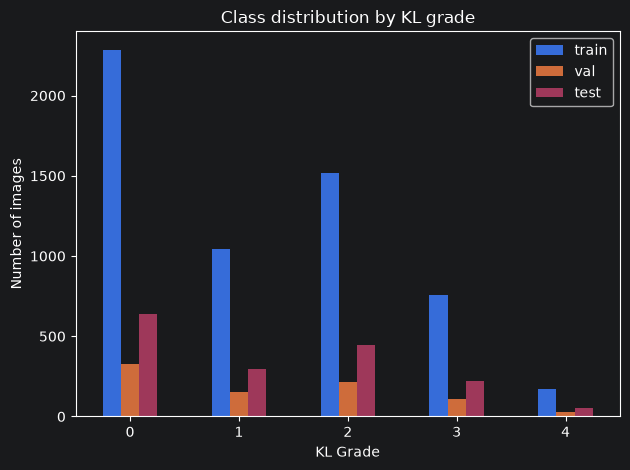

In [5]:
counts_df.plot(kind="bar")
plt.title("Class distribution by KL grade")
plt.xlabel("KL Grade")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The imbalance is severe: Grade 0 has roughly 13x as many training images as Grade 4, and
about 2.2x as many as Grade 1. This is the main reason a naive CNN collapses onto Grade 0
— predicting the majority class every time already gets ~39% "accuracy" for free. Class
weighting and QWK-based monitoring (both used below) exist specifically to counter this.

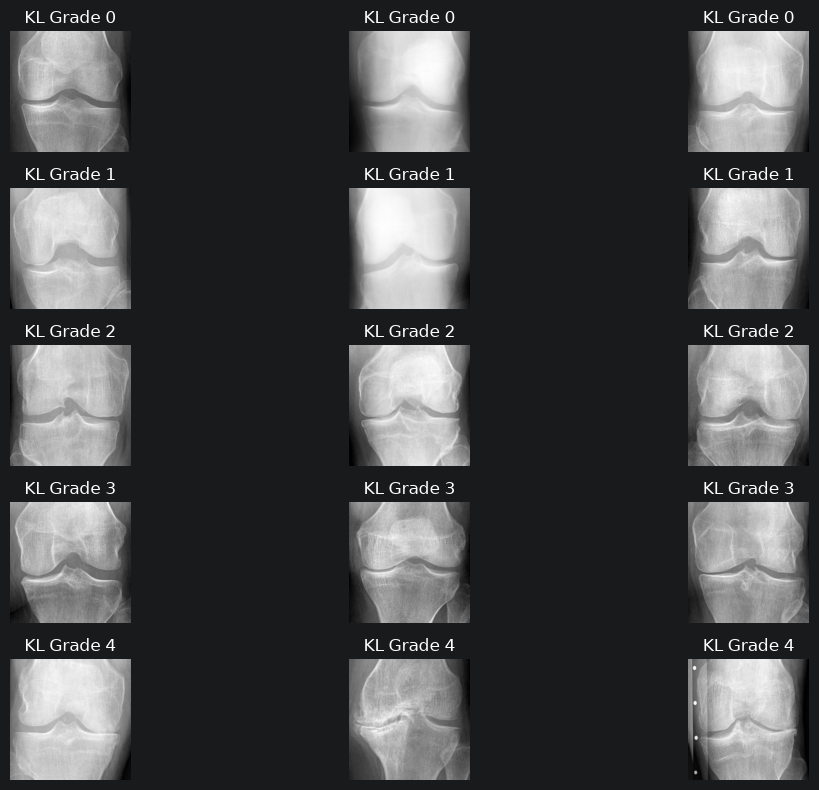

In [6]:
def show_sample_images(split_dir, n=3):
    class_folders = sorted(
        [f for f in split_dir.iterdir() if f.is_dir()], key=lambda p: int(p.name)
    )
    plt.figure(figsize=(12, 8))
    plot_idx = 1
    for class_folder in class_folders:
        image_files = list(class_folder.glob("*"))
        for img_path in random.sample(image_files, min(n, len(image_files))):
            img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
            plt.subplot(len(class_folders), n, plot_idx)
            plt.imshow(img, cmap="gray")
            plt.title(f"KL Grade {class_folder.name}")
            plt.axis("off")
            plot_idx += 1
    plt.tight_layout()
    plt.show()


show_sample_images(TRAIN_DIR, n=3)

## 3. Preprocessing

Three operations, applied in this order on the *original resolution* image (not on an
already-downscaled one, to avoid losing detail through a double resize):

1. **Centre crop** — X-rays typically have a wide margin of background/soft tissue around
   the knee joint; cropping brings the joint space closer to the centre of the frame.
2. **CLAHE** (Contrast Limited Adaptive Histogram Equalisation) — boosts local contrast
   around the joint space and osteophytes without blowing out the whole image the way
   global histogram equalisation would.
3. **Optional unsharp-mask sharpening** — accentuates the fine bone-edge detail that
   distinguishes Grade 0 from the subtle osteophytes of Grade 1. Off by default because it
   can also amplify noise; it's exposed as a toggle so it can be evaluated as an ablation.

In [7]:
def centre_crop_image(image, crop_fraction=CROP_FRACTION):
    height, width = image.shape[:2]
    crop_height = int(height * crop_fraction)
    crop_width = int(width * crop_fraction)
    start_y = (height - crop_height) // 2
    start_x = (width - crop_width) // 2
    return image[start_y:start_y + crop_height, start_x:start_x + crop_width]


def apply_clahe(image_uint8):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(image_uint8)


def unsharp_mask(image_uint8, sigma=1.0, strength=0.6):
    blurred = cv2.GaussianBlur(image_uint8, (0, 0), sigma)
    sharpened = cv2.addWeighted(image_uint8, 1 + strength, blurred, -strength, 0)
    return np.clip(sharpened, 0, 255).astype("uint8")


def preprocess_knee_xray(image_uint8, use_sharpening=False):
    """Crop -> resize -> CLAHE -> (optional) sharpen. Returns float32 in [0, 255]."""
    cropped = centre_crop_image(image_uint8)
    resized = cv2.resize(cropped, IMG_SIZE)
    enhanced = apply_clahe(resized)
    if use_sharpening:
        enhanced = unsharp_mask(enhanced)
    return enhanced.astype("float32")

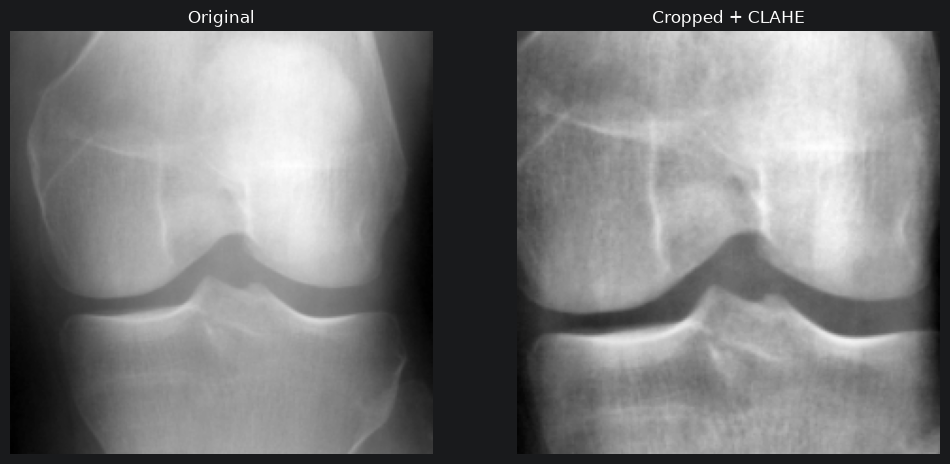

In [8]:
def show_before_after(original, processed):
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(original, cmap="gray")
    plt.title("Original")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(processed, cmap="gray")
    plt.title("Cropped + CLAHE")
    plt.axis("off")
    plt.show()


_sample_path = next((TRAIN_DIR / "0").glob("*"))
_sample_original = cv2.imread(str(_sample_path), cv2.IMREAD_GRAYSCALE)
_sample_processed = preprocess_knee_xray(_sample_original)
show_before_after(_sample_original, _sample_processed)

## 4. Efficient `tf.data` pipeline

Rather than loading every image into a NumPy array up front (memory-heavy and slow to
iterate on), we build a `tf.data.Dataset` of file paths and process each image lazily
inside `tf.numpy_function` (OpenCV isn't a native TensorFlow op, so this is the
straightforward way to call it from within a graph pipeline). Images stay in `[0, 255]`
float32 here; each model applies its own normalisation as its first layer so the same
datasets can feed either model without duplicating preprocessing logic.

In [9]:
def list_paths_and_labels(split_dir):
    class_folders = sorted(
        [f for f in split_dir.iterdir() if f.is_dir()], key=lambda p: int(p.name)
    )
    paths, labels = [], []
    for class_folder in class_folders:
        label = int(class_folder.name)
        for img_path in class_folder.glob("*"):
            paths.append(str(img_path))
            labels.append(label)
    return paths, labels


def _preprocess_from_path(path_tensor, use_sharpening):
    path = path_tensor.numpy().decode("utf-8")
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        # Corrupt/unreadable file - return a blank image rather than crashing the pipeline
        image = np.zeros((IMG_SIZE[0], IMG_SIZE[1]), dtype="uint8")
    processed = preprocess_knee_xray(image, use_sharpening=bool(use_sharpening))
    return processed[..., np.newaxis]  # add channel dim -> (H, W, 1)


def make_dataset(split_dir, batch_size=BATCH_SIZE, shuffle=False, augment_fn=None,
                  use_sharpening=False, cache=True):
    paths, labels = list_paths_and_labels(split_dir)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED, reshuffle_each_iteration=True)

    def _load(path, label):
        image = tf.py_function(
            func=lambda p: _preprocess_from_path(p, use_sharpening),
            inp=[path],
            Tout=tf.float32,
        )
        image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
        return image, label

    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)

    if cache:
        ds = ds.cache()  # cache the (small, already-preprocessed) tensors after first epoch

    if augment_fn is not None:
        ds = ds.map(lambda x, y: (augment_fn(x, training=True), y), num_parallel_calls=AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds, paths, labels

## 5. Augmentation (anatomically valid only)

The original baseline used `RandomFlip("horizontal_and_vertical")`. Vertical flipping a
knee X-ray produces an anatomically impossible image (an upside-down knee), which teaches
the model nothing useful and can hurt it. We keep only transformations a real X-ray could
plausibly exhibit: left/right mirroring, small rotations (patient positioning), a little
zoom/translation (framing), and mild contrast jitter (exposure differences).

In [10]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),        # ~±10.8 degrees
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.1),
], name="data_augmentation")

## 6. Build the datasets

In [11]:
train_ds, train_paths, train_labels = make_dataset(
    TRAIN_DIR, shuffle=True, augment_fn=data_augmentation
)
val_ds, val_paths, val_labels = make_dataset(VAL_DIR, shuffle=False, augment_fn=None)
test_ds, test_paths, test_labels = make_dataset(TEST_DIR, shuffle=False, augment_fn=None)

# A second copy of the training set WITHOUT augmentation is useful for quick sanity checks
train_ds_plain, _, _ = make_dataset(TRAIN_DIR, shuffle=False, augment_fn=None)

print(f"Train: {len(train_paths)} images | Val: {len(val_paths)} images | Test: {len(test_paths)} images")

Train: 5778 images | Val: 826 images | Test: 1656 images


## 7. Class weights

Computed directly from the label list (no need to load any images for this), and used in
`model.fit(..., class_weight=...)` so the loss penalises mistakes on rare classes (Grade 1,
Grade 4) more heavily than mistakes on the dominant Grade 0 class.

In [12]:
class_weights_array = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=np.array(train_labels),
)
class_weights = dict(enumerate(class_weights_array))
print("Class weights:", class_weights)

Class weights: {0: np.float64(0.5055118110236221), 1: np.float64(1.1047801147227534), 2: np.float64(0.7622691292875989), 3: np.float64(1.5265521796565389), 4: np.float64(6.679768786127168)}


## 8. Evaluation helpers

These are shared by every model we train below, so results are directly comparable.

In [13]:
def get_predictions(model, dataset):
    y_true, y_pred = [], []
    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(probabilities, axis=1))
    return np.array(y_true), np.array(y_pred)


def evaluate_model(model, dataset, model_name):
    y_true, y_pred = get_predictions(model, dataset)

    accuracy = float(np.mean(y_true == y_pred))
    qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
    grade1_recall = recall_score(y_true, y_pred, labels=[1], average=None)[0]
    grade1_precision = precision_score(y_true, y_pred, labels=[1], average=None, zero_division=0)[0]

    print(f"\n--- {model_name} ---")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))
    print(f"Accuracy: {accuracy:.3f} | QWK: {qwk:.3f} | "
          f"Grade 1 recall: {grade1_recall:.3f} | Grade 1 precision: {grade1_precision:.3f}")

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{model_name} — confusion matrix")
    plt.show()

    return {
        "model": model_name,
        "accuracy": accuracy,
        "qwk": qwk,
        "grade1_recall": grade1_recall,
        "grade1_precision": grade1_precision,
        "y_true": y_true,
        "y_pred": y_pred,
    }


class QWKCallback(tf.keras.callbacks.Callback):
    """Computes Quadratic Weighted Kappa on a held-out dataset after every epoch and
    exposes it as `val_qwk` in the logs dict, so EarlyStopping/ModelCheckpoint/etc. can
    monitor it directly — QWK is a much better signal than accuracy on this imbalanced,
    ordinal-label dataset."""

    def __init__(self, dataset):
        super().__init__()
        self.dataset = dataset

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        y_true, y_pred = get_predictions(self.model, self.dataset)
        qwk = cohen_kappa_score(y_true, y_pred, weights="quadratic")
        logs["val_qwk"] = qwk
        print(f" - val_qwk: {qwk:.4f}")


results = []  # collects one summary dict per model, used for the final comparison table

## 9. Model A — Improved custom CNN (trained from scratch)

Same family as the original baseline, but deeper and better regularised (batch
normalisation + L2 weight decay + dropout) since it now has to survive the extra pressure
of class weighting without overfitting to the reweighted minority classes.

In [14]:
def build_custom_cnn(input_shape=(*IMG_SIZE, 1), num_classes=NUM_CLASSES, l2_reg=1e-4):
    reg = tf.keras.regularizers.l2(l2_reg)

    def conv_block(x, filters):
        x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Conv2D(filters, 3, padding="same", kernel_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
        return x

    inputs = tf.keras.Input(shape=input_shape)
    x = layers.Rescaling(1.0 / 255)(inputs)

    x = conv_block(x, 32)
    x = conv_block(x, 64)
    x = conv_block(x, 128)
    x = conv_block(x, 256)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name="custom_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


custom_cnn = build_custom_cnn()
custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 56, 56, 128)    │             

 Total params: 1,242,597 (4.74 MB)

 Trainable params: 1,240,677 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
custom_cnn_callbacks = [
    QWKCallback(val_ds),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_qwk", mode="max", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "custom_cnn_best.keras"),
        monitor="val_qwk", mode="max", save_best_only=True,
    ),
]

history_custom_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=custom_cnn_callbacks,
)

Epoch 1/15


C:\Users\Warith2\PycharmProjects\-error-404-technical-challenge\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


169/181 ━━━━━━━━━━━━━━━━━━━━ 58s 5s/step - accuracy: 0.1666 - loss: 1.8119 

In [ ]:
custom_cnn_result = evaluate_model(custom_cnn, test_ds, "Custom CNN (from scratch)")
results.append(custom_cnn_result)

## 10. Model B — Transfer learning (MobileNetV2), fine-tuned

With ~9,800 images spread across 5 imbalanced classes, a from-scratch CNN has very little
signal per class to learn generic visual features (edges, textures, shapes) from. A
backbone pretrained on ImageNet already knows those general features; we only need to
adapt its later layers to X-ray-specific patterns, which needs far less data. This is
usually the strongest option for small medical imaging datasets, provided fine-tuning is
done carefully (frozen backbone first, then a slow, partial unfreeze) to avoid destroying
the pretrained features.

MobileNetV2 expects a 3-channel input, so a single-channel X-ray is replicated across the
RGB channels — this doesn't add information, but lets us reuse the pretrained filters
without retraining the whole network from random weights.

In [ ]:
def build_transfer_model(input_shape=(*IMG_SIZE, 1), num_classes=NUM_CLASSES, dropout=0.4):
    inputs = tf.keras.Input(shape=input_shape)
    x = layers.Concatenate()([inputs, inputs, inputs])  # grayscale -> pseudo-RGB
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet"
    )
    base_model.trainable = False

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name="transfer_mobilenetv2")
    return model, base_model


transfer_model, transfer_base = build_transfer_model()
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
transfer_model.summary()

### Stage 1 — train only the new classification head

The pretrained backbone stays frozen so its ImageNet weights aren't wrecked by large
gradient updates driven by a randomly-initialised head.

In [ ]:
head_callbacks = [
    QWKCallback(val_ds),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_qwk", mode="max", patience=5, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
]

history_transfer_head = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=head_callbacks,
)

### Stage 2 — fine-tune the top of the backbone

Unfreeze the last `FINE_TUNE_LAYERS` layers of MobileNetV2 and continue training with a
much smaller learning rate. BatchNorm layers are kept frozen — updating their running
statistics on a small, imbalanced batch tends to destabilise training.

In [ ]:
def unfreeze_top_layers(base_model, num_layers=FINE_TUNE_LAYERS):
    base_model.trainable = True
    for layer in base_model.layers[:-num_layers]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    return base_model


transfer_base = unfreeze_top_layers(transfer_base, FINE_TUNE_LAYERS)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

fine_tune_callbacks = [
    QWKCallback(val_ds),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_qwk", mode="max", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "transfer_mobilenetv2_best.keras"),
        monitor="val_qwk", mode="max", save_best_only=True,
    ),
]

history_transfer_finetune = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS + FINE_TUNE_EPOCHS,
    initial_epoch=len(history_transfer_head.history["loss"]),
    class_weight=class_weights,
    callbacks=fine_tune_callbacks,
)

In [ ]:
transfer_result = evaluate_model(transfer_model, test_ds, "Transfer learning (MobileNetV2, fine-tuned)")
results.append(transfer_result)

## 11. Training curves — both models side by side

In [ ]:
def concat_history(*histories, key):
    values = []
    for h in histories:
        values.extend(h.history[key])
    return values


plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_custom_cnn.history["accuracy"], label="Custom CNN — train")
plt.plot(history_custom_cnn.history["val_accuracy"], label="Custom CNN — val")
plt.plot(concat_history(history_transfer_head, history_transfer_finetune, key="accuracy"),
         label="Transfer model — train")
plt.plot(concat_history(history_transfer_head, history_transfer_finetune, key="val_accuracy"),
         label="Transfer model — val")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(fontsize="small")

plt.subplot(1, 2, 2)
plt.plot(history_custom_cnn.history["loss"], label="Custom CNN — train")
plt.plot(history_custom_cnn.history["val_loss"], label="Custom CNN — val")
plt.plot(concat_history(history_transfer_head, history_transfer_finetune, key="loss"),
         label="Transfer model — train")
plt.plot(concat_history(history_transfer_head, history_transfer_finetune, key="val_loss"),
         label="Transfer model — val")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(fontsize="small")

plt.tight_layout()
plt.show()

## 12. Results comparison

In [ ]:
results_df = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("y_true", "y_pred")} for r in results
])
results_df

In [ ]:
results_df.to_csv(RESULTS_DIR / "model_comparison.csv", index=False)
print(f"Saved comparison table to {RESULTS_DIR / 'model_comparison.csv'}")

## 13. Grad-CAM — where is the final model looking?

A quick interpretability check on the transfer-learning model: for a handful of test
images, Grad-CAM highlights the regions of the X-ray that most influenced the predicted
grade. For this to be trustworthy, the highlighted region should sit around the joint
space/osteophytes rather than, say, the image border or bone shaft. If it doesn't, that's
a sign the model has latched onto a spurious correlation (e.g. a scanner artefact) rather
than genuine disease features.

This helps us compare the results of the different models, and how a future model could be improved or better maintained

In [ ]:
def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name="Conv_1"):
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[base_model.get_layer(last_conv_layer_name).output, model.output],
    )
    # Rebuild a callable path from the *actual* model inputs through to the target conv
    # layer, since `base_model` is nested inside `model`.
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_array)
        predicted_class = tf.argmax(predictions[0])
        class_channel = predictions[:, predicted_class]

    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(predicted_class.numpy())


def show_gradcam(image_path, model, base_model, use_sharpening=False):
    original = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    processed = preprocess_knee_xray(original, use_sharpening=use_sharpening)
    img_array = processed[np.newaxis, ..., np.newaxis]

    heatmap, predicted_class = make_gradcam_heatmap(img_array, model, base_model)
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_colour = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    base_rgb = cv2.cvtColor(processed.astype("uint8"), cv2.COLOR_GRAY2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_colour, 0.4, 0)

    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(processed, cmap="gray")
    plt.title("Preprocessed input")
    plt.axis("off")
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"Grad-CAM (predicted {CLASS_NAMES[predicted_class]})")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# Show a few examples across grades, if their folders contain images
for grade in range(NUM_CLASSES):
    grade_dir = TEST_DIR / str(grade)
    sample_files = list(grade_dir.glob("*"))
    if sample_files:
        show_gradcam(str(random.choice(sample_files)), transfer_model, transfer_base)

## 14. Save the final model

The transfer-learning model is saved as the recommended final model based on the
comparison table above; swap this for `custom_cnn` if your own run shows the from-scratch
model performing better (results can vary run to run given the amount of data involved,
especially for the Grade 4 minority class).

In [ ]:
final_model_path = MODEL_DIR / "final_model.keras"
transfer_model.save(final_model_path)
print(f"Saved final model to {final_model_path}")

## 15. Summary

- The **custom CNN** shows how far careful preprocessing, class weighting and
  regularisation alone can take a from-scratch architecture on this dataset.
- The **transfer-learning model** starts from ImageNet features and fine-tunes them onto
  X-ray-specific patterns, which is generally the more data-efficient approach when only a
  few thousand images are available per class.
- Both are tracked on **Quadratic Weighted Kappa** and **Grade 1 recall/precision**
  specifically, not just accuracy, since accuracy alone can hide a model that has simply
  learned to predict the majority class.
- The Grad-CAM check gives a quick, qualitative sanity test that the final model is
  actually attending to the knee joint rather than an unrelated part of the image.

